📦 Inventory Management Analysis

Project Overview

This project focuses on analyzing inventory data to understand stock levels, sales performance, product availability, warehouse distribution, and inventory value to improve inventory management and business decisions.

Importing Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading Dataset

In [4]:
df = pd.read_excel(r"C:\Users\SHIVAM KUMAR\Downloads\inventory dataset.xlsx", header=1)

Initial Data Inspection

In [5]:
df.head()

,Date,Product,Category,Warehouse,Supplier,Quantity,Reorder Level,Stock Status,Unit Price (₹),Purchase Value (₹),Sales Qty,Sales Value (₹),Month,Inventory Value,Reorder QTY,Above Reorder QTY,Above Reorder Inventory Value
0,2025-01-01,WiFi Router,Electronics,HSR Hub,ABC Distributors,239,31,In Stock,250,18118.00,47,11458.98,Jan,59750,0,208,52000
1,2025-01-02,Refrigerator 250L,Home Appliances,MYS Hub,Metro Wholesale,204,32,In Stock,2800,143935.20,46,145636.92,Jan,571200,0,172,481600
2,2025-01-03,Notebook Premium,Office Supplies,HSR Hub,Greenline Trading,245,37,In Stock,18,627.44,2,38.65,Jan,4410,0,208,3744
3,2025-01-04,Vacuum Cleaner,Others,HSR Hub,Metro Wholesale,92,40,In Stock,1100,21649.06,10,10903.63,Jan,101200,0,52,57200
4,2025-01-05,WiFi Router,Electronics,HYD Hub,Global Supplies,181,22,In Stock,250,9802.30,42,10866.49,Jan,45250,0,159,39750


Display Last 5 Rows

In [6]:
df.tail()

,Date,Product,Category,Warehouse,Supplier,Quantity,Reorder Level,Stock Status,Unit Price (₹),Purchase Value (₹),Sales Qty,Sales Value (₹),Month,Inventory Value,Reorder QTY,Above Reorder QTY,Above Reorder Inventory Value
495,2026-05-11,Printer All-in-One,Office Supplies,MYS Hub,Global Supplies,107,11,In Stock,1200,13528.37,8,10320.58,May,128400,0,96,115200
496,2026-05-12,Microwave Oven,Home Appliances,KLR Hub,Prime Traders,163,32,In Stock,1200,7124.91,31,37726.26,May,195600,0,131,157200
497,2026-05-13,Wooden Table,Furniture,KLR Hub,Star Enterprises,127,25,In Stock,1500,11213.18,12,19384.40,May,190500,0,102,153000
498,2026-05-14,Air Conditioner 1.5T,Home Appliances,HYD Hub,Star Enterprises,201,39,In Stock,3500,201911.35,3,11471.98,May,703500,0,162,567000
499,2026-05-15,"LED TV 55""",Electronics,KLR Hub,Greenline Trading,193,16,In Stock,6000,89466.69,39,238093.91,May,1158000,0,177,1062000


Check Total Rows and Columns

In [7]:
df.shape

(500, 17)

Check Dataset Information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Date                           500 non-null    datetime64[ns]
 1   Product                        500 non-null    object        
 2   Category                       500 non-null    object        
 3   Warehouse                      500 non-null    object        
 4   Supplier                       500 non-null    object        
 5   Quantity                       500 non-null    int64         
 6   Reorder Level                  500 non-null    int64         
 7   Stock Status                   500 non-null    object        
 8   Unit Price (₹)                 500 non-null    int64         
 9   Purchase Value (₹)             500 non-null    float64       
 10  Sales Qty                      500 non-null    int64         
 11  Sales Value (₹)    

Statistical Summary

In [9]:
df.describe().round()

,Date,Quantity,Reorder Level,Unit Price (₹),Purchase Value (₹),Sales Qty,Sales Value (₹),Inventory Value,Reorder QTY,Above Reorder QTY,Above Reorder Inventory Value
count,500,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0
mean,2025-09-07 12:00:00,126.0,30.0,2024.0,35767.0,16.0,31912.0,256162.0,1.0,98.0,198153.0
min,2025-01-01 00:00:00,7.0,10.0,18.0,32.0,1.0,20.0,576.0,0.0,0.0,0.0
25%,2025-05-05 18:00:00,62.0,20.0,650.0,3503.0,5.0,3097.0,36900.0,0.0,32.0,12090.0
50%,2025-09-07 12:00:00,124.0,30.0,1200.0,14067.0,12.0,14178.0,146600.0,0.0,95.0,96150.0
75%,2026-01-10 06:00:00,188.0,40.0,2850.0,46094.0,24.0,35394.0,295500.0,0.0,158.0,230525.0
max,2026-05-15 00:00:00,250.0,50.0,8500.0,488761.0,59.0,299584.0,2116500.0,34.0,232.0,1904000.0
std,NaN,71.0,12.0,2112.0,57790.0,14.0,47706.0,338722.0,5.0,69.0,288892.0


Check Column Names 

In [10]:
df.columns

Index(['Date', 'Product', 'Category', 'Warehouse', 'Supplier', 'Quantity',
       'Reorder Level', 'Stock Status', 'Unit Price (₹)', 'Purchase Value (₹)',
       'Sales Qty', 'Sales Value (₹)', 'Month', 'Inventory Value',
       'Reorder QTY', 'Above Reorder QTY', 'Above Reorder Inventory Value'],
      dtype='object')

Data Cleaning

Check Missing Values

In [11]:
df.isnull().sum()

Date                             0
Product                          0
Category                         0
Warehouse                        0
Supplier                         0
Quantity                         0
Reorder Level                    0
Stock Status                     0
Unit Price (₹)                   0
Purchase Value (₹)               0
Sales Qty                        0
Sales Value (₹)                  0
Month                            0
Inventory Value                  0
Reorder QTY                      0
Above Reorder QTY                0
Above Reorder Inventory Value    0
dtype: int64

Check Total Missing Values

In [12]:
df.isnull().sum().sum()

np.int64(0)

Check Duplicate Records

In [13]:
df.duplicated().sum()

np.int64(0)

Remove Duplicate Records

In [14]:
df.drop_duplicates(inplace=True)

Standardize Column Names

In [15]:
df.columns = (df.columns
              .str.strip()
              .str.replace(" ", "_")
              .str.replace("(₹)", "INR", regex=False))

In [16]:
df.columns 

Index(['Date', 'Product', 'Category', 'Warehouse', 'Supplier', 'Quantity',
       'Reorder_Level', 'Stock_Status', 'Unit_Price_INR', 'Purchase_Value_INR',
       'Sales_Qty', 'Sales_Value_INR', 'Month', 'Inventory_Value',
       'Reorder_QTY', 'Above_Reorder_QTY', 'Above_Reorder_Inventory_Value'],
      dtype='object')

Standardize Text Columns

In [17]:
text_columns = ['Product', 'Category', 'Warehouse',
                'Supplier', 'Stock_Status', 'Month']

for col in text_columns:
    df[col] = df[col].str.strip()

Convert Data Types

In [18]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

numeric_columns = [
    'Quantity',
    'Reorder_Level',
    'Unit_Price_INR',
    'Purchase_Value_INR',
    'Sales_Qty',
    'Sales_Value_INR'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [19]:
df.dtypes 

Date                             datetime64[ns]
Product                                  object
Category                                 object
Warehouse                                object
Supplier                                 object
Quantity                                  int64
Reorder_Level                             int64
Stock_Status                             object
Unit_Price_INR                            int64
Purchase_Value_INR                      float64
Sales_Qty                                 int64
Sales_Value_INR                         float64
Month                                    object
Inventory_Value                           int64
Reorder_QTY                               int64
Above_Reorder_QTY                         int64
Above_Reorder_Inventory_Value             int64
dtype: object

Check Incorrect Values

In [20]:
df[numeric_columns].describe()

,Quantity,Reorder_Level,Unit_Price_INR,Purchase_Value_INR,Sales_Qty,Sales_Value_INR
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,126.256000,29.754000,2024.494000,35767.173020,15.982000,31912.081640
std,71.336444,11.979169,2112.105804,57789.877795,13.670532,47705.603209
min,7.000000,10.000000,18.000000,31.990000,1.000000,19.560000
25%,62.000000,20.000000,650.000000,3502.667500,5.000000,3097.255000
50%,124.500000,30.000000,1200.000000,14067.280000,12.000000,14178.350000
75%,188.000000,40.000000,2850.000000,46093.892500,24.000000,35393.875000
max,250.000000,50.000000,8500.000000,488761.410000,59.000000,299584.030000


Check  Negative values

In [21]:
(df[numeric_columns] < 0).sum()

Quantity              0
Reorder_Level         0
Unit_Price_INR        0
Purchase_Value_INR    0
Sales_Qty             0
Sales_Value_INR       0
dtype: int64

Check Zero values

In [22]:
(df[numeric_columns] == 0).sum()

Quantity              0
Reorder_Level         0
Unit_Price_INR        0
Purchase_Value_INR    0
Sales_Qty             0
Sales_Value_INR       0
dtype: int64

Check Inconsistent Values

In [23]:
print(df['Category'].unique())

print(df['Warehouse'].unique())

print(df['Supplier'].unique())

print(df['Stock_Status'].unique())

['Electronics' 'Home Appliances' 'Office Supplies' 'Others' 'Furniture']
['HSR Hub' 'MYS Hub' 'HYD Hub' 'KLR Hub' 'BLR Hub' 'CHN Hub']
['ABC Distributors' 'Metro Wholesale' 'Greenline Trading'
 'Global Supplies' 'National Suppliers' 'Prime Traders' 'Star Enterprises']
['In Stock' 'Low Stock' 'Out of Stock']


Validate Stock Status

In [24]:
df['Expected_Stock_Status'] = np.select(
    [
        df['Quantity'] == 0,
        df['Quantity'] <= df['Reorder_Level']
    ],
    [
        'Out of Stock',
        'Low Stock'
    ],
    default='In Stock'
)

In [25]:
df[df['Stock_Status'] != df['Expected_Stock_Status']]

,Date,Product,Category,Warehouse,Supplier,Quantity,Reorder_Level,Stock_Status,Unit_Price_INR,Purchase_Value_INR,Sales_Qty,Sales_Value_INR,Month,Inventory_Value,Reorder_QTY,Above_Reorder_QTY,Above_Reorder_Inventory_Value,Expected_Stock_Status
43,2025-02-13,Bluetooth Speaker,Electronics,HSR Hub,Metro Wholesale,47,32,Out of Stock,450,6274.84,5,2247.06,Feb,21150,0,15,6750,In Stock
53,2025-02-23,WiFi Router,Electronics,KLR Hub,Metro Wholesale,16,31,Out of Stock,250,826.72,1,240.78,Feb,4000,15,0,0,Low Stock
54,2025-02-24,Coffee Maker,Others,KLR Hub,Metro Wholesale,18,23,Out of Stock,650,1677.26,4,2679.67,Feb,11700,5,0,0,Low Stock
58,2025-02-28,Projector HD,Office Supplies,CHN Hub,Greenline Trading,42,44,Out of Stock,3000,38980.42,9,28855.40,Feb,126000,2,0,0,Low Stock
59,2025-03-01,Smartphone X1,Electronics,MYS Hub,Metro Wholesale,30,49,Out of Stock,4500,23636.42,1,4476.44,Mar,135000,19,0,0,Low Stock
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,2025-08-06,Projector HD,Office Supplies,KLR Hub,Global Supplies,154,15,Out of Stock,3000,42353.62,5,16151.14,Aug,462000,0,139,417000,In Stock
218,2025-08-07,Washing Machine,Home Appliances,HSR Hub,Global Supplies,98,50,Out of Stock,2200,9710.37,15,34482.57,Aug,215600,0,48,105600,In Stock
219,2025-08-08,Bluetooth Speaker,Electronics,HYD Hub,Star Enterprises,158,25,Out of Stock,450,11405.28,5,2181.52,Aug,71100,0,133,59850,In Stock
220,2025-08-09,Microwave Oven,Home Appliances,HYD Hub,Prime Traders,184,40,Out of Stock,1200,66138.12,39,53524.42,Aug,220800,0,144,172800,In Stock


Date Validation

In [26]:
df['Year'] = df['Date'].dt.year

df['Month_Number'] = df['Date'].dt.month

df['Month_Year'] = df['Date'].dt.strftime('%b-%Y')

In [27]:
df['Actual_Month'] = df['Date'].dt.strftime('%b')

df[df['Month'] != df['Actual_Month']]

,Date,Product,Category,Warehouse,Supplier,Quantity,Reorder_Level,Stock_Status,Unit_Price_INR,Purchase_Value_INR,...,Month,Inventory_Value,Reorder_QTY,Above_Reorder_QTY,Above_Reorder_Inventory_Value,Expected_Stock_Status,Year,Month_Number,Month_Year,Actual_Month


Feature Engineering

Calculate Inventory Value

In [28]:
df['Inventory_Value'] = (
    df['Quantity'] * df['Unit_Price_INR']
)

Calculate Reorder Quantity

In [29]:
df['Reorder_QTY'] = np.where(
    df['Quantity'] <= df['Reorder_Level'],
    df['Reorder_Level'] - df['Quantity'],
    0
)

Calculate Above Reorder Inventory Value

In [30]:
df['Above_Reorder_Inventory_Value'] = (
    df['Above_Reorder_QTY'] * df['Unit_Price_INR']
)

Check Calculated Columns

In [31]:
df[[
    'Quantity',
    'Reorder_Level',
    'Unit_Price_INR',
    'Inventory_Value',
    'Reorder_QTY',
    'Above_Reorder_QTY',
    'Above_Reorder_Inventory_Value'
]].head(10)

,Quantity,Reorder_Level,Unit_Price_INR,Inventory_Value,Reorder_QTY,Above_Reorder_QTY,Above_Reorder_Inventory_Value
0,239,31,250,59750,0,208,52000
1,204,32,2800,571200,0,172,481600
2,245,37,18,4410,0,208,3744
3,92,40,1100,101200,0,52,57200
4,181,22,250,45250,0,159,39750
5,127,21,8500,1079500,0,106,901000
6,62,33,3500,217000,0,29,101500
7,95,50,4500,427500,0,45,202500
8,218,31,650,141700,0,187,121550
9,126,16,1400,176400,0,110,154000


In [48]:
df.to_excel("Cleaned_Inventory.xlsx",index=False)
print("succesfull")

succesfull


Exploratory Data Analysis

Category-wise Sales

In [33]:
category_sales = df.groupby(
    'Category'
)['Sales_Value_INR'].sum().sort_values(ascending=False)

print(category_sales)

Category
Electronics        7706131.85
Home Appliances    3584240.88
Office Supplies    1842862.84
Others             1485097.35
Furniture          1337707.90
Name: Sales_Value_INR, dtype: float64


Warehouse-wise Inventory

In [34]:
warehouse_inventory = df.groupby(
    'Warehouse'
)['Inventory_Value'].sum().sort_values(ascending=False)

print(warehouse_inventory)

Warehouse
HYD Hub    45909372
HSR Hub    20144465
MYS Hub    19194927
BLR Hub    19051039
KLR Hub    13856537
CHN Hub     9924870
Name: Inventory_Value, dtype: int64


Top 10 Selling Products

In [35]:
top_products = df.groupby(
    'Product'
)['Sales_Value_INR'].sum().sort_values(ascending=False).head(10)

print(top_products)

Product
LED TV 55"              2996351.45
Laptop Pro 15           2458546.87
Smartphone X1           2003159.99
Refrigerator 250L       1380924.74
Projector HD            1195777.11
Washing Machine          844102.55
Air Conditioner 1.5T     780382.88
Water Purifier           615554.50
Microwave Oven           578830.71
Wooden Table             567800.25
Name: Sales_Value_INR, dtype: float64


Stock Status Analysis

In [36]:
df['Stock_Status'].value_counts()

Stock_Status
In Stock        343
Out of Stock    114
Low Stock        43
Name: count, dtype: int64

Monthly Sales Analysis

In [37]:
monthly_sales = df.groupby(
    'Month_Year'
)['Sales_Value_INR'].sum()

print(monthly_sales)

Month_Year
Apr-2025     807116.95
Apr-2026     674107.91
Aug-2025    1172373.53
Dec-2025     760278.66
Feb-2025     889355.33
Feb-2026     949077.52
Jan-2025    1293454.69
Jan-2026     822665.15
Jul-2025    1065434.05
Jun-2025    1076239.60
Mar-2025    1219919.99
Mar-2026     566249.35
May-2025    1152360.81
May-2026     820528.19
Nov-2025     791245.76
Oct-2025    1080547.74
Sep-2025     815085.59
Name: Sales_Value_INR, dtype: float64


Data Visualization

Category-wise Sales – Bar Chart

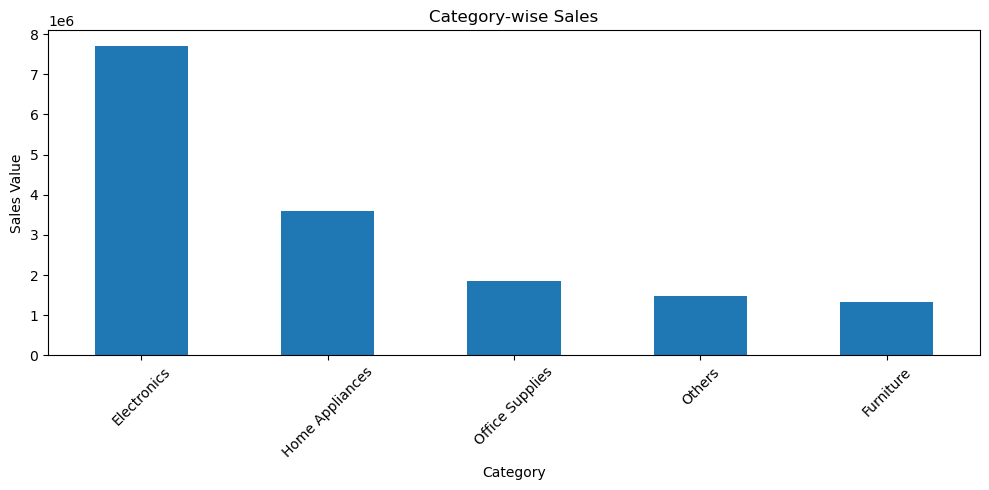

In [38]:
category_sales.plot(kind='bar', figsize=(10,5))

plt.title('Category-wise Sales')
plt.xlabel('Category')
plt.ylabel('Sales Value')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Stock Status – Pie Chart

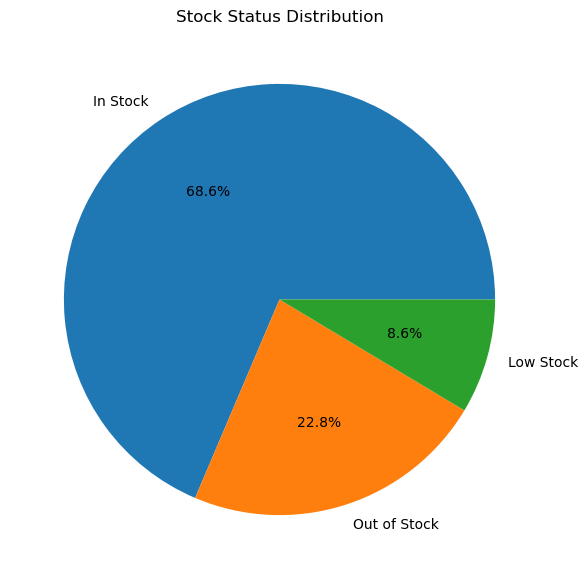

In [39]:
df['Stock_Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7)
)

plt.title('Stock Status Distribution')
plt.ylabel('')
plt.show()

Monthly Sales Trend – Line Chart

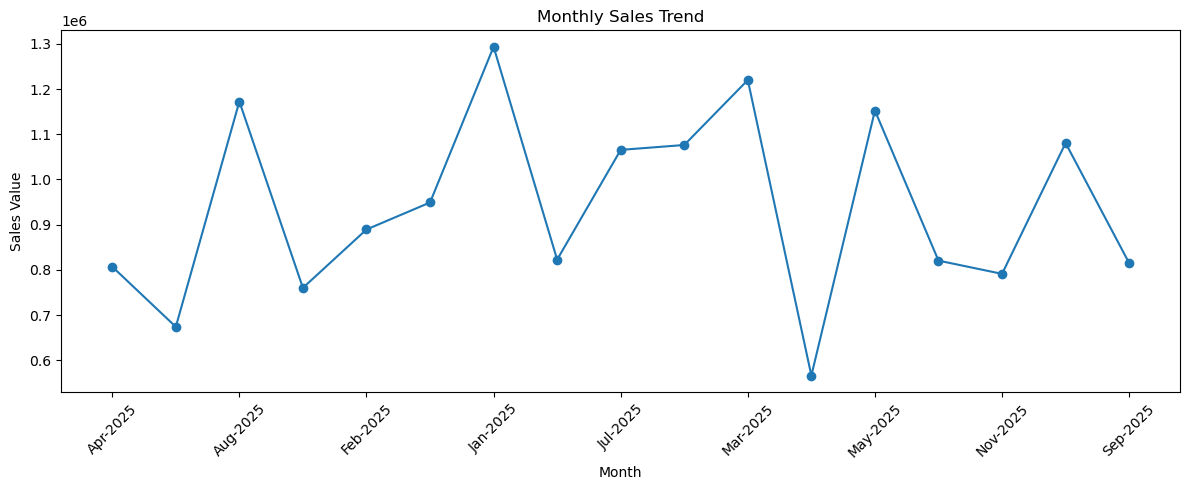

In [40]:
monthly_sales.plot(
    kind='line',
    marker='o',
    figsize=(12,5)
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Value')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Products – Bar Chart

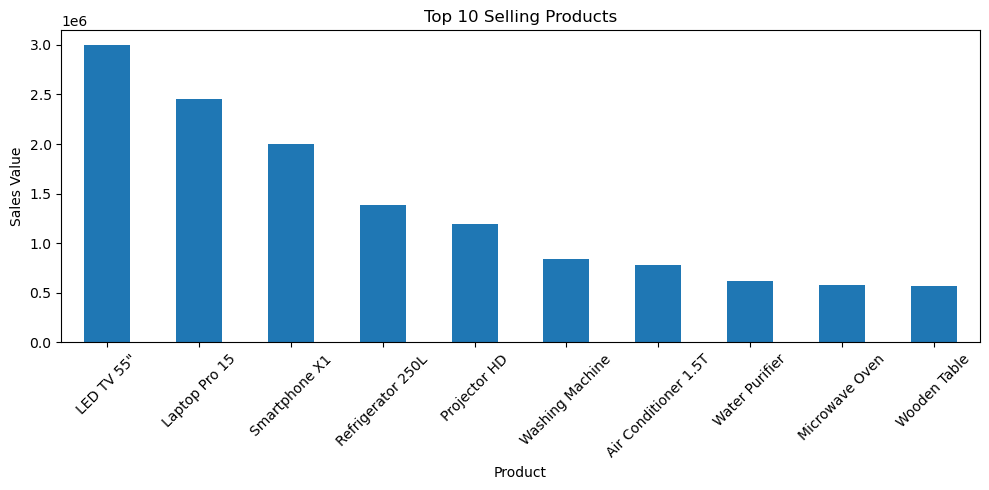

In [41]:
top_products.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Selling Products')
plt.xlabel('Product')
plt.ylabel('Sales Value')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation Heatmap

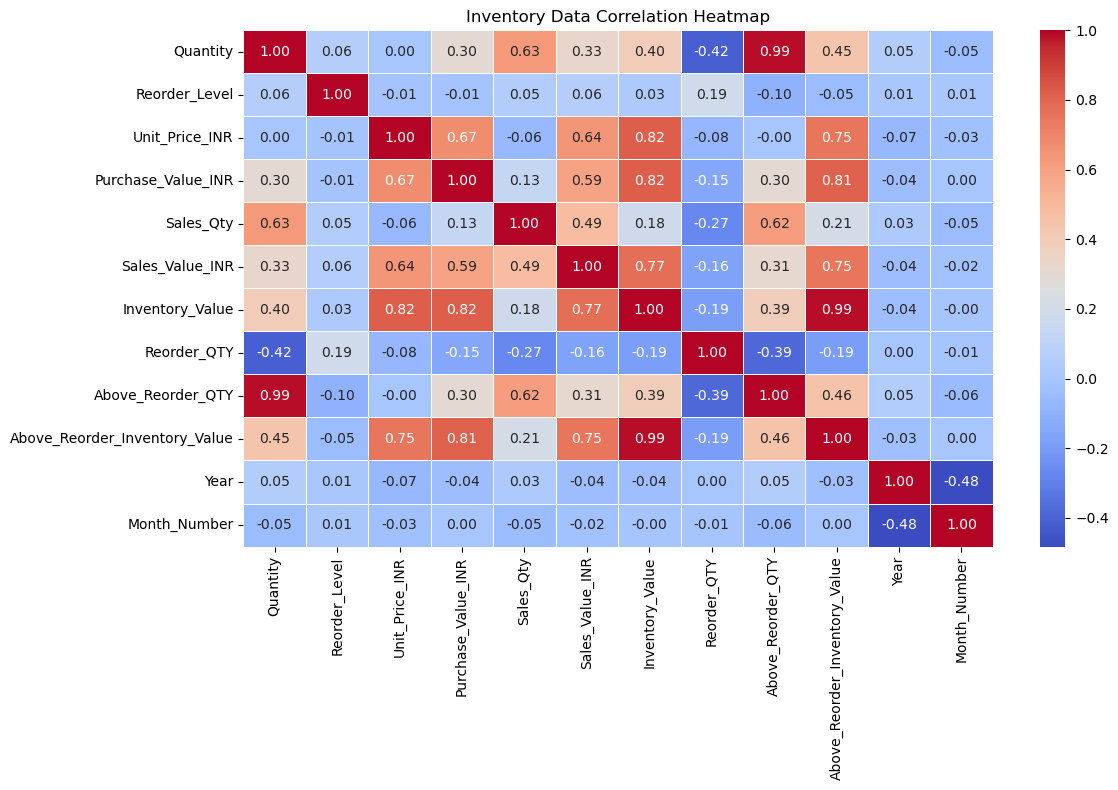

In [42]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include='number'
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Inventory Data Correlation Heatmap')
plt.tight_layout()
plt.show()

Histogram

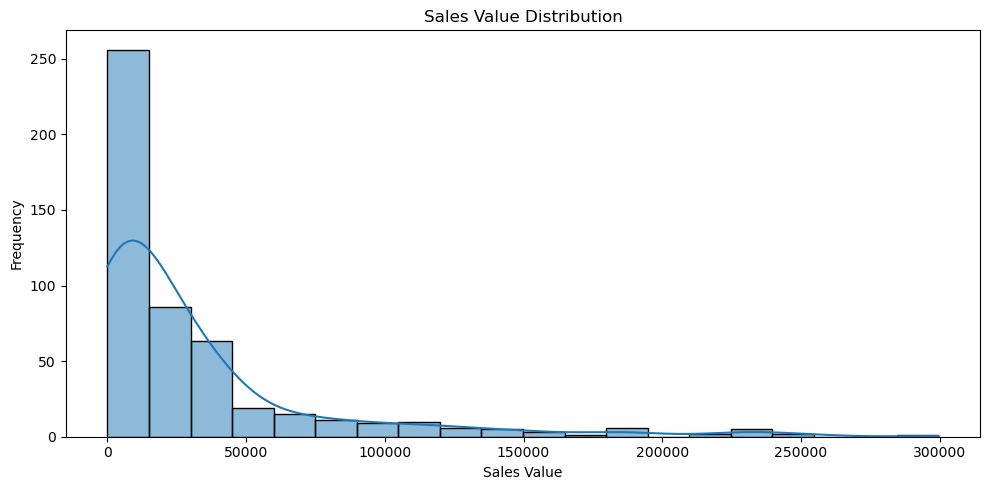

In [43]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Sales_Value_INR',
    bins=20,
    kde=True
)

plt.title('Sales Value Distribution')
plt.xlabel('Sales Value')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Box Plot

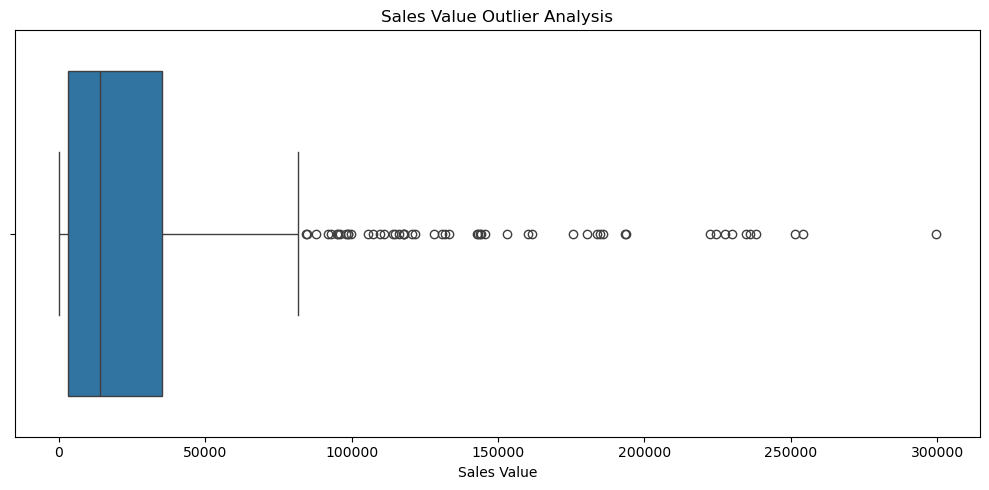

In [44]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='Sales_Value_INR'
)

plt.title('Sales Value Outlier Analysis')
plt.xlabel('Sales Value')

plt.tight_layout()
plt.show()

Scatter Plot

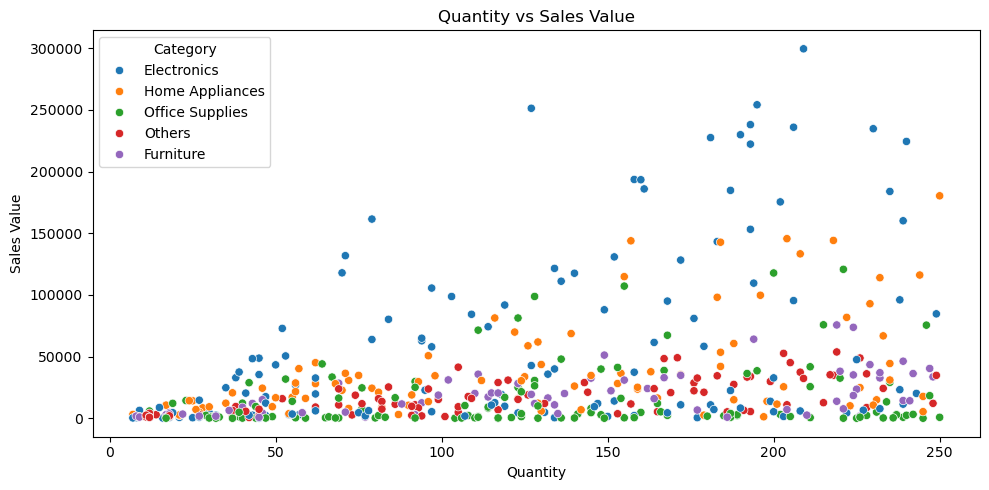

In [45]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Sales_Value_INR',
    hue='Category'
)

plt.title('Quantity vs Sales Value')
plt.xlabel('Quantity')
plt.ylabel('Sales Value')

plt.tight_layout()
plt.show()

Code for MySQL

In [46]:
!pip install pymysql sqlalchemy

In [47]:
from sqlalchemy import create_engine
# MySQL connection
username = "root"
password = "root"
host = "localhost"
port = "3306"
database = "Inventory"

engine = create_engine(f"mysql+pymysql://{"root"}:{"root"}@{host}:{port}/{database}")

# Write DataFrame to MySQL
table_name = "user"   # choose any table name
df.to_sql(table_name, engine, if_exists="replace", index=False)

# Read back sample
pd.read_sql("SELECT * FROM user LIMIT 5;", engine)

,Date,Product,Category,Warehouse,Supplier,Quantity,Reorder_Level,Stock_Status,Unit_Price_INR,Purchase_Value_INR,...,Month,Inventory_Value,Reorder_QTY,Above_Reorder_QTY,Above_Reorder_Inventory_Value,Expected_Stock_Status,Year,Month_Number,Month_Year,Actual_Month
0,2025-01-01,WiFi Router,Electronics,HSR Hub,ABC Distributors,239,31,In Stock,250,18118.00,...,Jan,59750,0,208,52000,In Stock,2025,1,Jan-2025,Jan
1,2025-01-02,Refrigerator 250L,Home Appliances,MYS Hub,Metro Wholesale,204,32,In Stock,2800,143935.20,...,Jan,571200,0,172,481600,In Stock,2025,1,Jan-2025,Jan
2,2025-01-03,Notebook Premium,Office Supplies,HSR Hub,Greenline Trading,245,37,In Stock,18,627.44,...,Jan,4410,0,208,3744,In Stock,2025,1,Jan-2025,Jan
3,2025-01-04,Vacuum Cleaner,Others,HSR Hub,Metro Wholesale,92,40,In Stock,1100,21649.06,...,Jan,101200,0,52,57200,In Stock,2025,1,Jan-2025,Jan
4,2025-01-05,WiFi Router,Electronics,HYD Hub,Global Supplies,181,22,In Stock,250,9802.30,...,Jan,45250,0,159,39750,In Stock,2025,1,Jan-2025,Jan
